## 1. Setup

In [1]:
from __future__ import annotations
import sys
from pathlib import Path

PROJECT_ROOT = Path().resolve().parents[1]   # Desktop/Materias/ML/Final Project
W4_SRC = PROJECT_ROOT / "workshops" / "w4" / "src"
for _p in (str(W4_SRC),):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from constants import CHECKPOINTS_DIR, RUNS_DIR, FIGURES_DIR, SEED
from autoencoder.data_loader import load_w1_data, filter_normal
from autoencoder.autoencoder_vae import VAE, VAEConfig, ELBOLoss
from train.train_vae import VAETrainer, save_checkpoint, load_checkpoint, build_loader, set_seed
from evaluate.evaluate_vae import VAEEvaluator
from train.train_ae import load_checkpoint as ae_load_checkpoint

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cpu


## 2. Data & preprocessor

In [2]:
df, y_all, features, categorical_cols, numeric_cols, split = load_w1_data()
fit_idx, stop_idx = filter_normal(split, y_all)

# Load the pre-fitted preprocessor from ae_best.pt (do NOT refit)
_, _, prep, _, _ = ae_load_checkpoint(CHECKPOINTS_DIR / "ae_best.pt", device)
print(f"Preprocessor loaded  |  numeric_dim={prep.numeric_dim}  input_dim={prep.input_dim}")

x_num_fit,  x_cat_fit  = prep.transform(df.iloc[fit_idx])
x_num_stop, x_cat_stop = prep.transform(df.iloc[stop_idx])

test_idx = split["test"]
df_test  = df.iloc[test_idx].reset_index(drop=True)
y_test   = y_all[test_idx]        # numpy array
x_num_test, x_cat_test = prep.transform(df_test)

print(f"fit_normal  : {len(x_num_fit):,}")
print(f"stop_normal : {len(x_num_stop):,}")
print(f"test        : {len(x_num_test):,}  (churn={y_test.sum():,})")

train_feb rows:   992,931 | label month: 2017-02 | churn rate: 0.0639
test      rows:   970,960 | label month: 2017-03 | churn rate: 0.0899
labelled cohorts: (1963891, 63) | users in both labelled months: 881701
Preprocessor loaded  |  numeric_dim=55  input_dim=117
fit_normal  : 697,095
stop_normal : 116,183
test        : 970,960  (churn=87,330)


## 3. Train beta sweep {0.5, 1.0, 4.0}

In [3]:
BETAS = [0.5, 1.0, 4.0]
vae_models    = {}
vae_histories = {}

for beta in BETAS:
    print(f"\n{'='*55}")
    print(f"  Training VAE  beta={beta}")
    print(f"{'='*55}")
    set_seed(SEED)
    config = VAEConfig(
        numeric_dim       = prep.numeric_dim,
        cat_cardinalities = prep.cat_cardinalities,
        z_dim             = 16,
        beta              = beta,
        kl_anneal_epochs  = 10,
        max_epochs        = 50,
        patience          = 5,
    )
    model   = VAE(config).to(device)
    trainer = VAETrainer(model, config, device)
    history = trainer.fit(
        build_loader(x_num_fit,  x_cat_fit,  config.batch_size, shuffle=True),
        build_loader(x_num_stop, x_cat_stop, config.batch_size, shuffle=False),
    )
    ckpt_path = CHECKPOINTS_DIR / f"vae_beta{beta}.pt"
    save_checkpoint(ckpt_path, model, config, prep, history, trainer.best_epoch)
    history.to_csv(RUNS_DIR / f"vae_beta{beta}_history.csv", index=False)

    vae_models[beta]    = model
    vae_histories[beta] = history
    print(f"  Saved -> {ckpt_path.name}  |  best_epoch={trainer.best_epoch}")


  Training VAE  beta=0.5


c:\Users\Usuario\Desktop\Materias\ML\Final Project\env\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  epoch   1  beta_t=0.050  train=17.0611  val=25.8992  (recon=6.4231  kl=38.9521  au=16)
  epoch   5  beta_t=0.250  train=10.7261  val=14.1151  (recon=3.7676  kl=20.6949  au=15)
  epoch  10  beta_t=0.500  train=13.8360  val=11.2190  (recon=3.8894  kl=14.6591  au=15)
  epoch  15  beta_t=0.500  train=13.3590  val=10.9358  (recon=3.6957  kl=14.4803  au=15)
  epoch  20  beta_t=0.500  train=13.1024  val=10.6291  (recon=3.6213  kl=14.0155  au=15)
  epoch  25  beta_t=0.500  train=12.9435  val=10.6274  (recon=3.5640  kl=14.1267  au=15)
  Early stop at epoch 26 (best=21, val=10.57492)
  Saved -> vae_beta0.5.pt  |  best_epoch=21

  Training VAE  beta=1.0


c:\Users\Usuario\Desktop\Materias\ML\Final Project\env\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  epoch   1  beta_t=0.100  train=18.6287  val=36.5516  (recon=6.7103  kl=29.8412  au=16)
  epoch   5  beta_t=0.500  train=14.7553  val=19.2516  (recon=4.8097  kl=14.4418  au=14)
  epoch  10  beta_t=1.000  train=19.7076  val=15.8363  (recon=5.9436  kl=9.8927  au=14)
  epoch  15  beta_t=1.000  train=19.2901  val=15.5959  (recon=5.9884  kl=9.6075  au=13)
  epoch  20  beta_t=1.000  train=19.0264  val=15.3998  (recon=5.8995  kl=9.5003  au=13)
  epoch  25  beta_t=1.000  train=18.8222  val=15.3846  (recon=5.9202  kl=9.4643  au=13)
  Early stop at epoch 27 (best=22, val=15.30433)
  Saved -> vae_beta1.0.pt  |  best_epoch=22

  Training VAE  beta=4.0


c:\Users\Usuario\Desktop\Materias\ML\Final Project\env\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  epoch   1  beta_t=0.400  train=23.9458  val=61.9836  (recon=9.5889  kl=13.0987  au=11)
  epoch   5  beta_t=2.000  train=27.1126  val=33.8414  (recon=11.0080  kl=5.7083  au=9)
  epoch  10  beta_t=4.000  train=34.6257  val=29.5956  (recon=16.1252  kl=3.3676  au=7)
  epoch  15  beta_t=4.000  train=34.1033  val=29.5947  (recon=16.3832  kl=3.3029  au=7)
  epoch  20  beta_t=4.000  train=33.7190  val=29.3221  (recon=16.3872  kl=3.2337  au=7)
  epoch  25  beta_t=4.000  train=33.5404  val=29.0718  (recon=16.2063  kl=3.2164  au=6)
  Early stop at epoch 26 (best=21, val=28.95804)
  Saved -> vae_beta4.0.pt  |  best_epoch=21


## 4. Training curves per beta

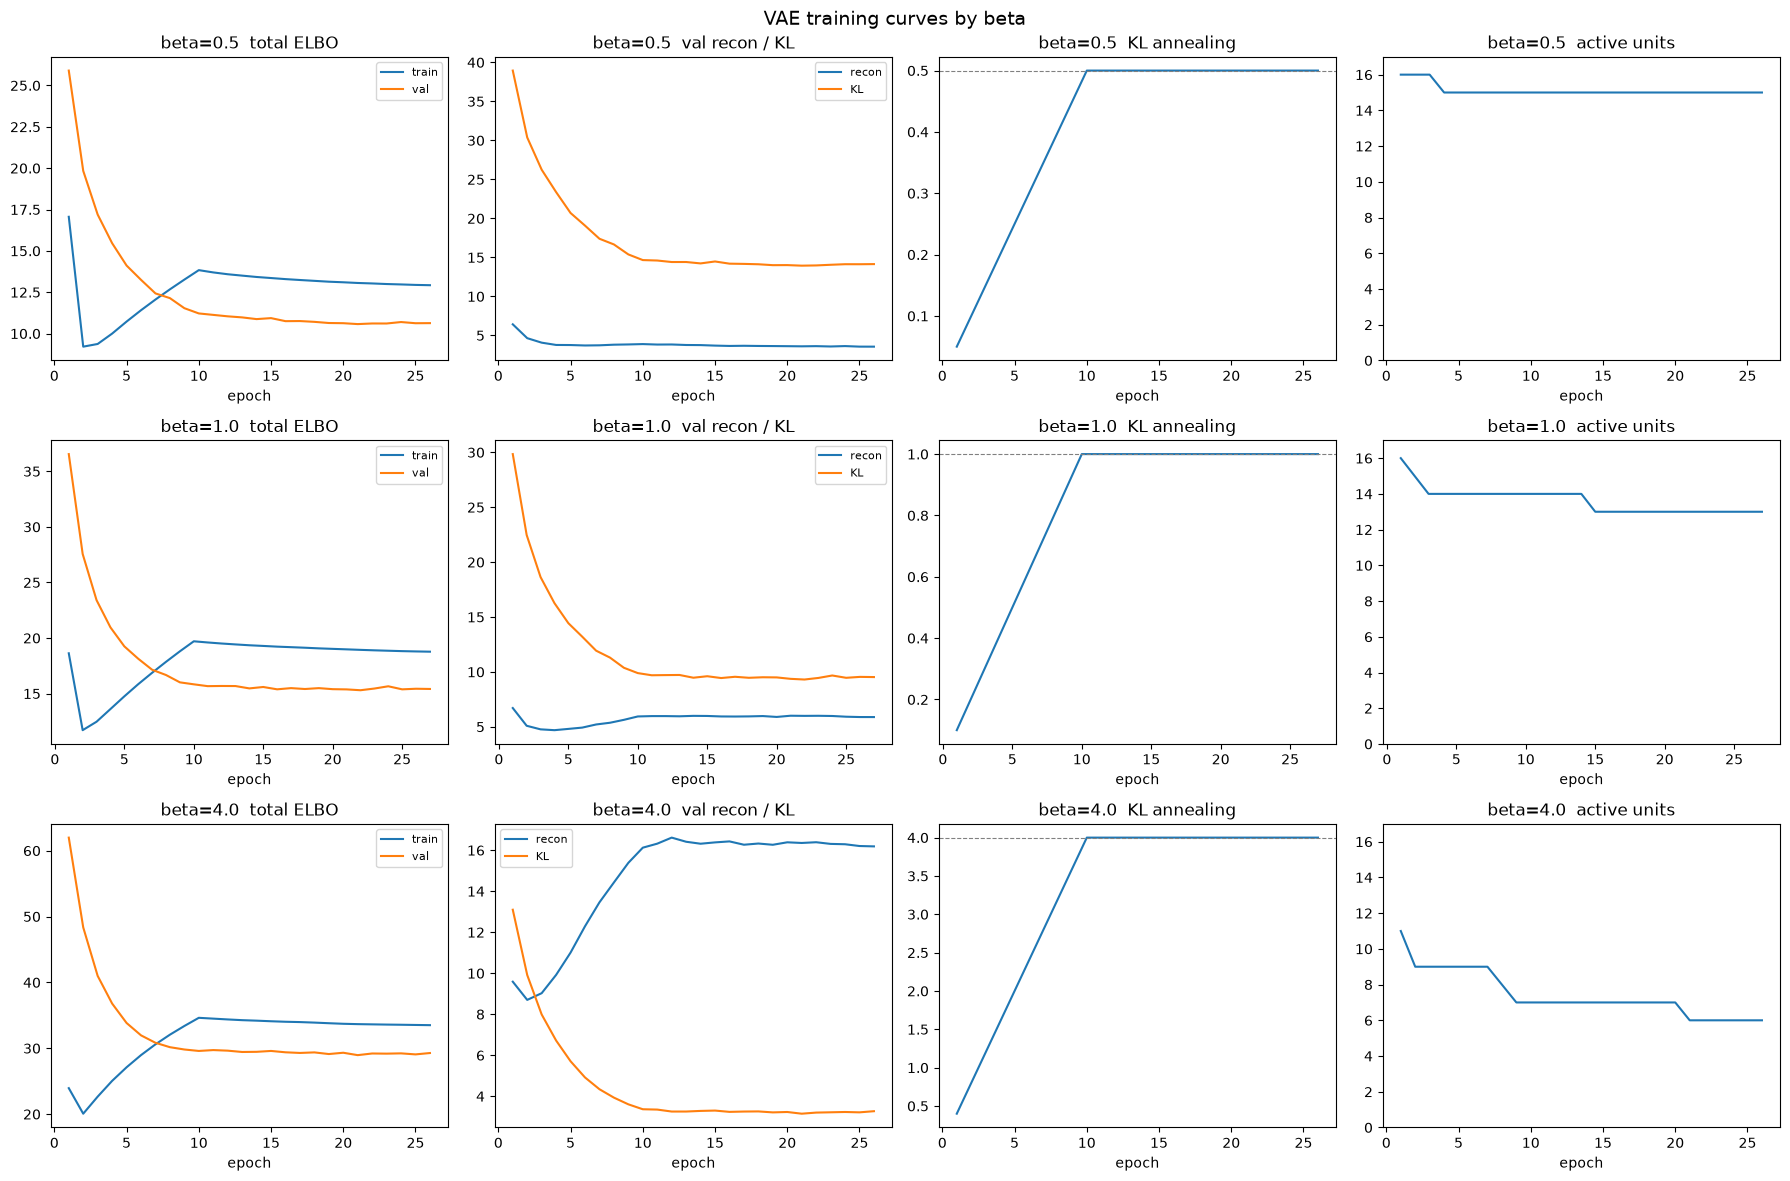

In [4]:
fig, axes = plt.subplots(len(BETAS), 4, figsize=(18, 4 * len(BETAS)))
fig.suptitle("VAE training curves by beta", fontsize=14)

for row, beta in enumerate(BETAS):
    h = vae_histories[beta]

    axes[row, 0].plot(h["epoch"], h["train_loss"], label="train")
    axes[row, 0].plot(h["epoch"], h["val_loss"],   label="val")
    axes[row, 0].set_title(f"beta={beta}  total ELBO")
    axes[row, 0].legend(fontsize=8)

    axes[row, 1].plot(h["epoch"], h["val_recon"], label="recon")
    axes[row, 1].plot(h["epoch"], h["val_kl"],    label="KL")
    axes[row, 1].set_title(f"beta={beta}  val recon / KL")
    axes[row, 1].legend(fontsize=8)

    axes[row, 2].plot(h["epoch"], h["beta_t"])
    axes[row, 2].axhline(beta, linestyle="--", color="gray", linewidth=0.8)
    axes[row, 2].set_title(f"beta={beta}  KL annealing")

    axes[row, 3].plot(h["epoch"], h["active_units"])
    axes[row, 3].set_ylim(0, 17)
    axes[row, 3].set_title(f"beta={beta}  active units")

for ax in axes.flat:
    ax.set_xlabel("epoch")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "vae_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Comparison table across beta values

In [5]:
from sklearn.metrics import silhouette_score

rows = []

for beta in BETAS:
    model = vae_models[beta]
    h     = vae_histories[beta]
    ev    = VAEEvaluator(model, prep, device)

    sm_val = ev.summary_metrics(x_num_stop, x_cat_stop)
    _, _, mu_val, _ = ev.predict(x_num_stop, x_cat_stop)
    au = int((mu_val.var(dim=0) > 0.01).sum())

    sil = ev.latent_separability(x_num_test, x_cat_test, y_test, seed=SEED)

    rows.append({
        "beta":              beta,
        "val_recon":         float(h["val_recon"].iloc[-1]),
        "val_kl":            float(h["val_kl"].iloc[-1]),
        "mse_per_element":   float(h["val_mse_per_element"].iloc[-1]),
        "cat_acc_city":      sm_val["cat_accuracy"].get("city", float("nan")),
        "active_units":      au,
        "silhouette_test":   sil,
    })

comp_df = pd.DataFrame(rows)
print(comp_df.to_string(index=False))

 beta  val_recon    val_kl  mse_per_element  cat_acc_city  active_units  silhouette_test
  0.5   3.560547 14.144028         0.043166      0.687553            15         0.142741
  1.0   5.887851  9.530893         0.079033      0.676312            13         0.161997
  4.0  16.188388  3.272493         0.252258      0.644018             6         0.241070


## 6. Choose vae_best

Lower beta: better reconstruction, weaker regularisation.
Higher beta: more structured latent space (higher silhouette), worse reconstruction.
beta=1.0 is the canonical VAE. Adjust `BEST_BETA` if the table suggests otherwise.

In [6]:
BEST_BETA = 1.0   # adjust after inspecting the table above

import shutil
best_src = CHECKPOINTS_DIR / f"vae_beta{BEST_BETA}.pt"
best_dst = CHECKPOINTS_DIR / "vae_best.pt"
shutil.copy(best_src, best_dst)
print(f"vae_best.pt -> copy of vae_beta{BEST_BETA}.pt")

vae_best, cfg_best, _, _, _ = load_checkpoint(best_dst, device)
ev_best = VAEEvaluator(vae_best, prep, device)

vae_best.pt -> copy of vae_beta1.0.pt


## 7. Test evaluation of vae_best

In [7]:
# Per-class reconstruction errors
num_out_t, cat_logits_t, mu_t, logvar_t = ev_best.predict(x_num_test, x_cat_test)

_elbo = ELBOLoss()
_, recon_i, _, _ = _elbo(
    num_out_t, x_num_test, cat_logits_t, x_cat_test,
    mu_t, logvar_t, beta=1.0, reduction="none",
)
vae_errors = recon_i.numpy()

print(f"MSE per element (test): {ev_best.summary_metrics(x_num_test, x_cat_test)['mse_numeric']:.6f}")
print()
print(ev_best.metrics_by_class(vae_errors, y_test).to_string(index=False))

MSE per element (test): 0.094320

 class      n  mean_error  median_error
normal 883630    6.159822      5.225780
 churn  87330   14.265275     10.134628


In [8]:
# Top-10 hardest features
vae_pfm = ev_best.per_feature_metrics(x_num_test, x_cat_test)
print("Top-10 hardest features:")
print(vae_pfm.nlargest(10, "mse").to_string(index=False))

Top-10 hardest features:
                    feature      mse  pearson_corr
           expire_dayofweek 0.351305      0.876379
             days_to_expire 0.266892      0.910519
         registration_month 0.241045      0.967857
days_since_last_transaction 0.195759      0.917481
             n_amounts_paid 0.181389      0.912608
                 difference 0.177339      0.907652
        last_third_ratio_25 0.176265      0.913428
           login_difference 0.171427      0.934109
          registration_year 0.161395      0.923803
               more_than_30 0.156092      0.928154


In [9]:
# Sample panel: 8 test clients — original vs VAE reconstruction
import random
panel_idx = random.Random(SEED).sample(range(len(x_num_test)), 8)
x_num_p   = x_num_test[panel_idx]
x_cat_p   = x_cat_test[panel_idx]
df_orig_p = df_test.iloc[panel_idx].reset_index(drop=True)

panel = ev_best.sample_panel(x_num_p, x_cat_p, df_orig_p)
print("=== Reconstruction panel (first 8 numeric cols) ===")
print(panel[prep.numeric_cols_nc[:8]].to_string())

=== Reconstruction panel (first 8 numeric cols) ===
                        bd  bd_missing  tenure_days  registration_year  registration_month  has_member_record  is_cancel_change_flag  is_auto_renew_change_flag
original      0  29.971142         1.0  1126.000000        2014.000000            1.000000                1.0                    0.0                        1.0
              1  29.971142         1.0   127.000000        2016.000000           10.000000                1.0                    0.0                        1.0
              2  34.000000         0.0  1375.000000        2013.000000            5.000000                1.0                    1.0                        1.0
              3  29.971142         1.0   470.000000        2015.000000           11.000000                1.0                    1.0                        1.0
              4  37.000000         0.0  2273.000000        2010.000000           12.000000                1.0                    0.0                

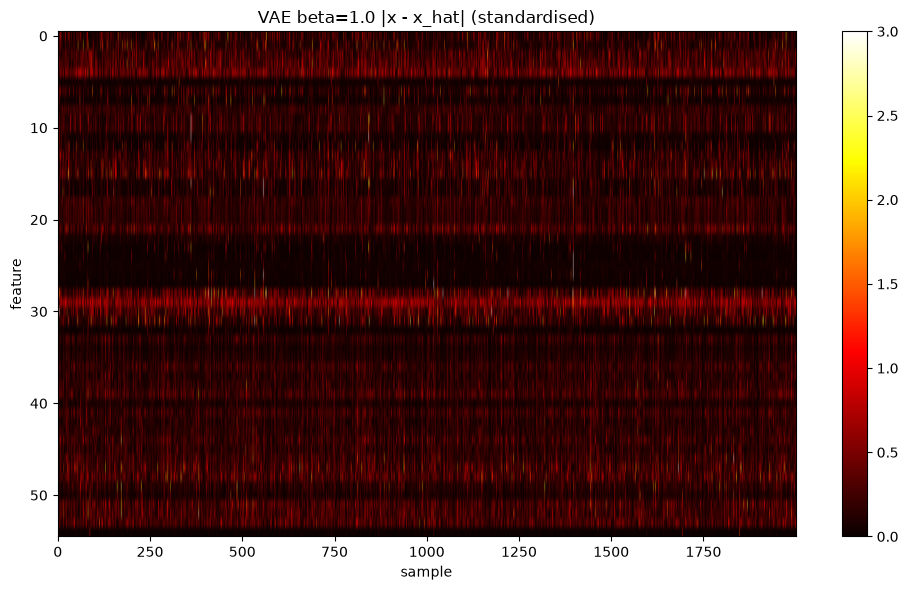

In [10]:
# Difference heatmap
vae_diff = ev_best.difference_matrix(x_num_test, x_cat_test)

rng_h = np.random.default_rng(SEED)
idx_h = rng_h.choice(len(vae_diff), 2000, replace=False)

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(vae_diff[idx_h].T, aspect="auto", cmap="hot", vmin=0, vmax=3)
ax.set_title(f"VAE beta={BEST_BETA} |x - x_hat| (standardised)")
ax.set_xlabel("sample"); ax.set_ylabel("feature")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "vae_difference_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. KL per latent dimension (vae_best)

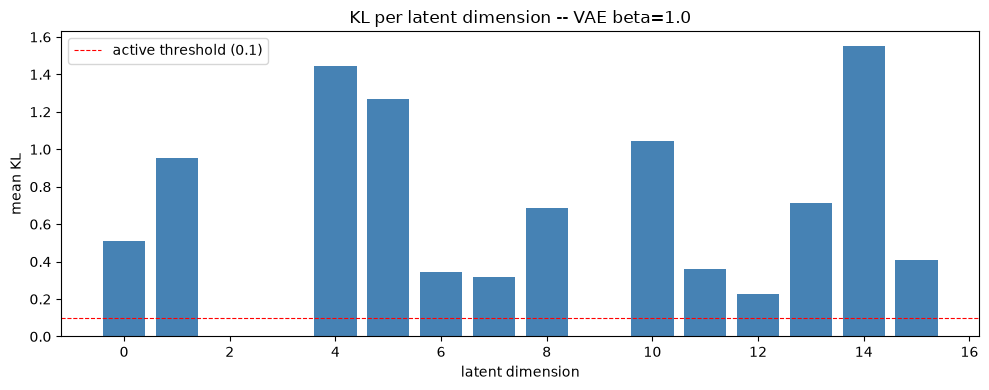

Active dims (KL>0.1): 13 / 16


In [11]:
_, _, mu_test, logvar_test = ev_best.predict(x_num_test, x_cat_test)
kl_dims = ev_best.kl_per_dimension(mu_test, logvar_test)

fig, ax = plt.subplots(figsize=(10, 4))
dims = np.arange(len(kl_dims))
ax.bar(dims, kl_dims, color=np.where(kl_dims > 0.1, "steelblue", "lightgray"))
ax.axhline(0.1, linestyle="--", color="red", linewidth=0.8, label="active threshold (0.1)")
ax.set_xlabel("latent dimension")
ax.set_ylabel("mean KL")
ax.set_title(f"KL per latent dimension -- VAE beta={BEST_BETA}")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "vae_kl_per_dim.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Active dims (KL>0.1): {int((kl_dims > 0.1).sum())} / {len(kl_dims)}")

## 9. Generative demo — 8 clients sampled from N(0, I)

The VAE's structured prior allows sampling directly from the latent space.

Generated clients (59 columns):
          bd  bd_missing  tenure_days  registration_year  registration_month  has_member_record  is_cancel_change_flag  is_auto_renew_change_flag  transaction_count  average_amount_paid  average_amount_charged  average_plan  n_payment_methods   n_plans  n_list_prices  n_amounts_paid   duration  plan_coverage_ratio  sum_plan_days  sum_list_price  sum_amount_paid  more_than_30  autorenew_not_cancel  not_autorenew_cancel  max_plan_days  last_plan_days  last_is_auto_renew  last_is_cancel  last_discount  days_to_expire  expire_dayofweek  days_since_last_transaction  difference  has_transactions  sum_last_month_unq  sum_last_month_total_secs  mean_last_month_total_secs  last_login  last_sum_total_songs  last_ratio_100  last_ratio_25  sum_last_second_month_total_secs  last_second_login  last_second_sum_total_songs  last_second_ratio_100  last_second_ratio_25  last_third_sum_total_songs  last_third_ratio_100  last_third_ratio_25  login_difference  trend_songs  t

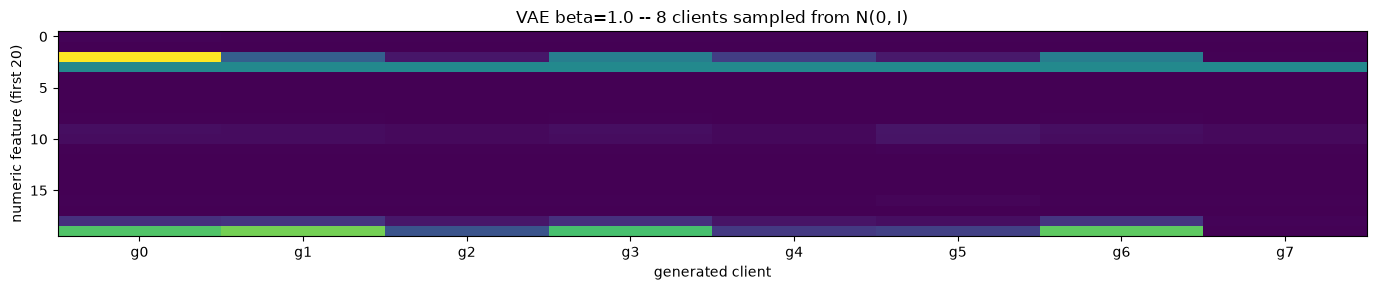

In [12]:
set_seed(SEED)
gen_df = ev_best.generate_samples(8)
print("Generated clients (59 columns):")
print(gen_df.to_string())

fig, ax = plt.subplots(figsize=(14, 3))
ax.imshow(gen_df[prep.numeric_cols_nc[:20]].to_numpy().T, aspect="auto", cmap="viridis")
ax.set_xlabel("generated client")
ax.set_ylabel("numeric feature (first 20)")
ax.set_title(f"VAE beta={BEST_BETA} -- 8 clients sampled from N(0, I)")
ax.set_xticks(range(8)); ax.set_xticklabels([f"g{i}" for i in range(8)])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "vae_generative_demo.png", dpi=120, bbox_inches="tight")
plt.show()